# Sobreturismo y vivienda vacacional en Gran Canaria

## 1. Introducción y caso de uso
Canarias depende del turismo, pero la conversión de viviendas en **viviendas vacacionales (VV)** reduce la oferta residencial y presiona los precios. Este análisis se centra en **Gran Canaria**.

**Preguntas**
1. ¿Cuántos turistas recibió Gran Canaria este verano (2026)?
2. ¿Cuándo fue el pico y cuántos turistas hubo?
3. ¿Cuánta vivienda vacacional hay y cómo se reparte?
4. (Dato extra) ¿Qué isla soporta más turistas por habitante?

**Hipótesis**
- H1: El verano concentra el mayor número de turistas del año. *(Ojo: en Gran Canaria el pico suele ser en invierno, comprobarlo.)*
- H2: La VV está concentrada en pocos municipios turísticos del sur.
- H3: Gran Canaria no es la isla con más presión turística por habitante.

**Plan de acción:** si se confirma la concentración de VV, el argumento para la regulación por zonas (Ley 6/2025, límite del 10% por municipio) queda respaldado con datos.

## 2. Fuentes de datos
- ISTAC · FRONTUR: turistas por isla y mes.
- ISTAC · Estadística experimental de vivienda vacacional.
- ISTAC/INE · Padrón por isla.

Los CSV se guardan en `src/data/` (ver README).

In [14]:
import sys
sys.path.append("utils")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import helpers as h

sns.set_theme(style="whitegrid")

turistas_raw = h.cargar_csv("frontur_mensual.csv")
turistas_raw.head()

,fecha,isla,turistas
0,2010-01-01,Fuerteventura,95278.0
1,2010-02-01,Fuerteventura,97400.0
2,2010-03-01,Fuerteventura,128303.0
3,2010-04-01,Fuerteventura,100129.0
4,2010-05-01,Fuerteventura,105076.0


## 3. Exploración inicial y limpieza

In [15]:
print(turistas_raw.shape)
print(turistas_raw.dtypes)
print(turistas_raw.isna().sum())

turistas = h.limpiar_serie_mensual(turistas_raw, "turistas")
turistas.describe()

(995, 3)
fecha        object
isla         object
turistas    float64
dtype: object
fecha       0
isla        0
turistas    0
dtype: int64
Duplicados eliminados: 0 | Filas con fecha/valor nulo eliminadas: 0


,fecha,turistas,anio,mes
count,995,995.000000,995.000000,995.000000
mean,2018-04-24 17:36:28.944723712,225681.920603,2017.859296,6.452261
min,2010-01-01 00:00:00,5.000000,2010.000000,1.000000
25%,2014-02-01 00:00:00,99094.500000,2014.000000,3.000000
50%,2018-04-01 00:00:00,205843.000000,2018.000000,6.000000
75%,2022-08-01 00:00:00,337659.500000,2022.000000,9.000000
max,2026-09-01 00:00:00,679245.000000,2026.000000,12.000000
std,NaN,163960.714090,4.858180,3.444951


## 4. Análisis: turistas en Gran Canaria este verano

In [16]:
resumen = h.resumen_verano(turistas, isla="Gran Canaria", anio=2026)
resumen

{'isla': 'Gran Canaria',
 'anio': 2026,
 'meses_incluidos': ['jun', 'jul', 'ago'],
 'total_verano': 1055298,
 'mes_pico': 'jul',
 'turistas_mes_pico': 375331}

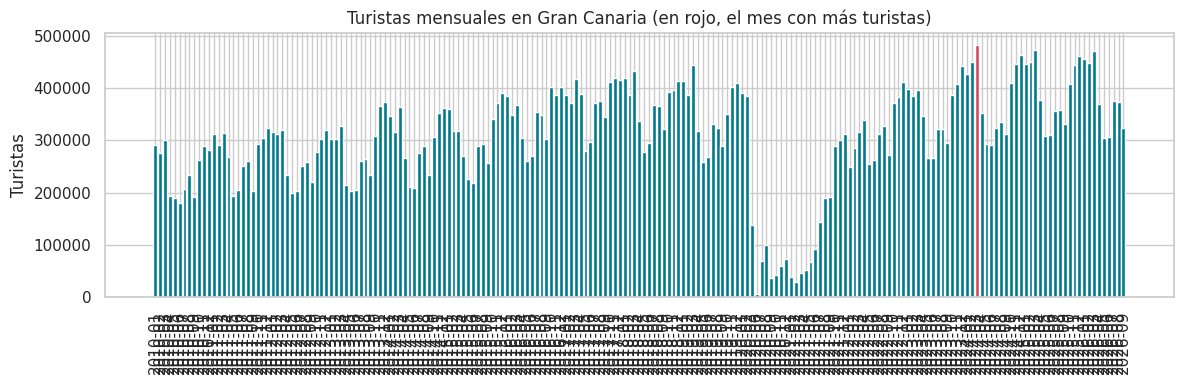

Mes con más turistas de toda la serie: 2024-03 (481,665)


In [6]:
gc = turistas[turistas["isla"] == "Gran Canaria"].copy()
gc["etiqueta"] = gc["fecha"].dt.strftime("%Y-%m")

pico_global = gc.loc[gc["turistas"].idxmax()]
colores = ["#d1495b" if f == pico_global["fecha"] else "#00798c" for f in gc["fecha"]]

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(gc["etiqueta"], gc["turistas"], color=colores)
ax.set_title("Turistas mensuales en Gran Canaria (en rojo, el mes con más turistas)")
ax.set_ylabel("Turistas")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print(f"Mes con más turistas de toda la serie: {pico_global['etiqueta']} ({int(pico_global['turistas']):,})")

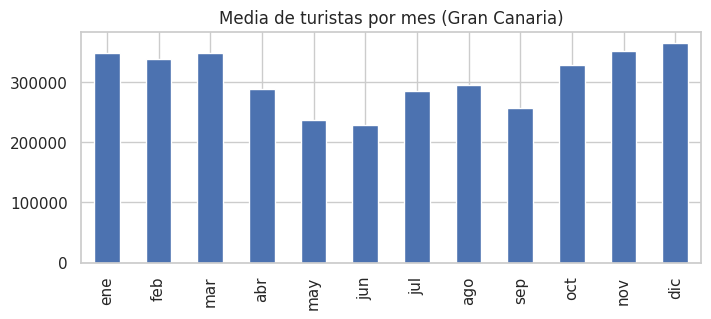

In [7]:
# Estacionalidad: media mensual por mes del año (¿verano o invierno?)
estacionalidad = gc.groupby("mes")["turistas"].mean().round(0)
estacionalidad.index = [h.MESES_ES[m] for m in estacionalidad.index]
estacionalidad.plot(kind="bar", figsize=(8, 3), title="Media de turistas por mes (Gran Canaria)")
plt.show()

## 5. Dato extra: presión turística por isla
Turistas del año por habitante. Solo para mencionarlo en la presentación.

In [8]:
poblacion = h.cargar_csv("poblacion_islas.csv")
# Usa un año completo (p. ej. 2025) para que la comparación sea justa
presion = h.turistas_por_habitante(turistas, poblacion, anio=2025)
presion

,isla,turistas,habitantes,turistas_por_habitante
0,Fuerteventura,2709596.0,129541.0,20.92
1,Lanzarote,3292549.0,167406.0,19.67
2,Tenerife,7412046.0,961745.0,7.71
3,Gran Canaria,4725554.0,870608.0,5.43
4,La Palma,202200.0,86194.0,2.35


## 6. Vivienda vacacional

In [9]:
vv_raw = h.cargar_csv("vivienda_vacacional.csv")
vv = h.limpiar_serie_mensual(vv_raw, "viviendas")

ultimo = vv[vv["fecha"] == vv["fecha"].max()].sort_values("viviendas", ascending=False)
ultimo["%_del_total"] = (100 * ultimo["viviendas"] / ultimo["viviendas"].sum()).round(1)
ultimo[["isla", "viviendas", "%_del_total"]]

Duplicados eliminados: 0 | Filas con fecha/valor nulo eliminadas: 0


,isla,viviendas,%_del_total
650,Tenerife,19148,41.0
644,Gran Canaria,9643,20.6
646,Lanzarote,7785,16.7
648,Fuerteventura,6672,14.3
645,La Palma,2020,4.3
649,La Gomera,888,1.9
647,El Hierro,550,1.2


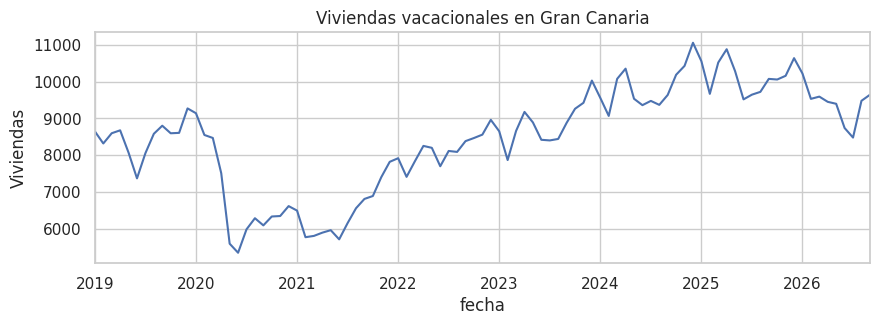

In [10]:
# Evolución de la VV en Gran Canaria
vv_gc = vv[vv["isla"] == "Gran Canaria"]
ax = vv_gc.plot(x="fecha", y="viviendas", figsize=(10, 3), legend=False,
                title="Viviendas vacacionales en Gran Canaria")
ax.set_ylabel("Viviendas")
plt.show()

In [11]:
# Concentración de la VV por municipio en Gran Canaria (último mes disponible)
muni = pd.read_csv("data/vv_municipios.csv", parse_dates=["fecha"])
gc_m = muni[(muni["isla"] == "Gran Canaria") & (muni["fecha"] == muni["fecha"].max())]
gc_m = gc_m.sort_values("viviendas", ascending=False)
gc_m["%_isla"] = (100 * gc_m["viviendas"] / gc_m["viviendas"].sum()).round(1)
gc_m["%_acumulado"] = gc_m["%_isla"].cumsum().round(1)
gc_m.head(8)[["municipio", "viviendas", "%_isla", "%_acumulado"]]

,municipio,viviendas,%_isla,%_acumulado
1952,San Bartolomé de Tirajana,3426,35.5,35.5
1673,Las Palmas de Gran Canaria,2306,23.9,59.4
1766,Mogán,1754,18.2,77.6
2417,Telde,375,3.9,81.5
929,Agaete,247,2.6,84.1
1022,Agüimes,246,2.6,86.7
2138,Santa Lucía de Tirajana,199,2.1,88.8
1394,Gáldar,149,1.5,90.3


In [12]:
# Vivienda vacacional por cada 1.000 habitantes (último mes)
ult = vv[vv["fecha"] == vv["fecha"].max()].merge(poblacion, on="isla")
ult["vv_por_1000_hab"] = (1000 * ult["viviendas"] / ult["habitantes"]).round(1)
ult.sort_values("vv_por_1000_hab", ascending=False)[["isla", "viviendas", "habitantes", "vv_por_1000_hab"]]

,isla,viviendas,habitantes,vv_por_1000_hab
4,Fuerteventura,6672,129541.0,51.5
2,Lanzarote,7785,167406.0,46.5
3,El Hierro,550,12040.0,45.7
5,La Gomera,888,22442.0,39.6
1,La Palma,2020,86194.0,23.4
6,Tenerife,19148,961745.0,19.9
0,Gran Canaria,9643,870608.0,11.1


## 7. Conclusiones

*(Cifras de los datos ISTAC descargados: FRONTUR hasta septiembre de 2026, vivienda vacacional hasta septiembre de 2026, población a 1 de enero de 2025.)*

**Verano 2026 en Gran Canaria (junio-agosto, turistas principales)**
- Total: **1.055.298 turistas** (+2,9% sobre el verano de 2025).
- Pico: **julio, con 375.331 turistas** (agosto casi igual: 373.226).

**Contraste de hipótesis**
- **H1 (el verano concentra el mayor número de turistas): NO se cumple.** Gran Canaria es un destino de invierno: marzo de 2026 (470.348) y diciembre de 2025 (461.447) superan al pico del verano.
- **H2 (la VV está concentrada en pocos municipios): SÍ.** San Bartolomé de Tirajana (35,5%), Las Palmas de Gran Canaria (23,9%) y Mogán (18,2%) suman el 77,6% de las 9.643 viviendas vacacionales de la isla.
- **H3 (Gran Canaria no es la isla con más presión turística por habitante): SÍ.** Fuerteventura (20,9 turistas por habitante al año) y Lanzarote (19,7) están muy por encima de Tenerife (7,7) y Gran Canaria (5,4). Con la vivienda vacacional pasa lo mismo: 51,5 por cada 1.000 habitantes en Fuerteventura frente a 11,1 en Gran Canaria.

**Matices**
- La vivienda vacacional reduce la oferta residencial, pero con estos datos no se puede afirmar que *infle los precios*: faltarían datos de precios de alquiler o compra.
- Desde la Ley 6/2025 (diciembre de 2025) la VV de Gran Canaria baja: de 10.638 (diciembre de 2025) a 9.643 (septiembre de 2026), aunque entre julio y agosto de 2026 hay un salto en todas las islas que no se explica con estos datos.
- En el dataset de turistas solo están 5 islas (no La Gomera ni El Hierro).
- Turistas por habitante compara llegadas anuales con la población a 1 de enero; no mide cuánta gente hay a la vez en la isla.

**Plan de acción / oportunidades:** regulación por zonas (los tres municipios con más VV son donde más importa el límite del 10%), seguimiento mensual con ISTAC, y ampliar el análisis con precios del alquiler.
